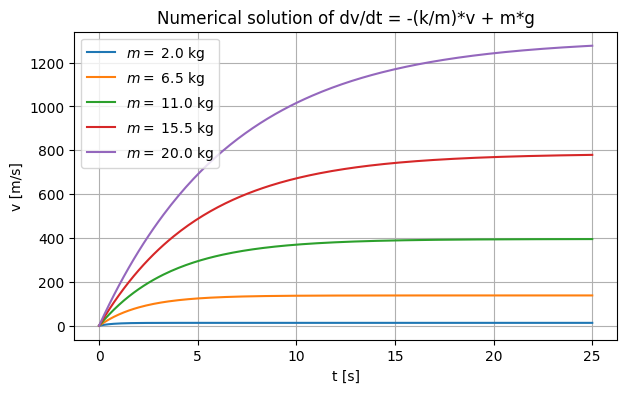

In [16]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Parameters
k = 3.0     # damping coefficient
massas = np.linspace(2, 20, 5)     # mass
g = 9.81    # gravitational acceleration
v0 = 0.0    # initial velocity
t_end = 25

velocidades_list = []
tempos_list = []
for m in massas:
    # Differential equation: dv/dt = -(k/m)*v + m*g
    def f(t, v):
        return - (k / m) * v + m * g

    # Time grid
    t_span = (0.0, t_end)
    t_eval = np.linspace(t_span[0], t_span[1], 200)

    # Numerical integration
    sol = solve_ivp(f, t_span, [v0], t_eval=t_eval, rtol=1e-9, atol=1e-12)

    # Extract results
    t = sol.t
    v = sol.y[0]
    velocidades_list.append(v)
    tempos_list.append(t)

# Plot
plt.figure(figsize=(7,4))
for ii in range(len(massas)):
    plt.plot(tempos_list[ii], velocidades_list[ii], label=f"$m=$ {massas[ii]} kg")

plt.xlabel("t [s]")
plt.ylabel("v [m/s]")
plt.title("Numerical solution of dv/dt = -(k/m)*v + m*g")
plt.grid(True)
plt.legend()
plt.show()
